# Figura 2: seções de Poincaré e expoente de Lyapunov

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU-USUARIO/pendulo-caotico/blob/main/02_secoes_de_poincare_e_lyapunov.ipynb)

Notebook de apoio ao artigo *Caracterização do caos no pêndulo forçado e amortecido: instabilidade, informação e geometria do espaço de fase*, **Seção III, Figura 2**.

Os dois diagnósticos padrão da dinâmica caótica são aplicados às mesmas duas trajetórias, uma no regime periódico ($f = 0{,}9$) e outra no caótico ($f = 1{,}2$). Os painéis (a) e (b) mostram as seções de Poincaré, que dão a representação geométrica. Os painéis (c) e (d) mostram a estimativa do maior expoente de Lyapunov ao longo do tempo, que é o teste de instabilidade.

**Tempo de execução:** cerca de 10 segundos.

## Equações

O sistema é a Eq. (3) do artigo,

$$\dot\theta = \omega, \qquad \dot\omega = -q\,\omega - \sin\theta + f\cos(\Omega t),$$

com $q = 0{,}5$ e $\Omega = 2/3$. No código, $q$ aparece com o nome `beta`.

**Seção de Poincaré (mapa estroboscópico), Eq. (4).** O estado é amostrado uma vez por período do forçamento, $T_d = 2\pi/\Omega = 3\pi$:

$$x_n = x(t_0 + nT_d).$$

Uma órbita de período $T_d$ aparece como um único ponto; uma de período $kT_d$, como $k$ pontos; um atrator caótico, como um conjunto com estrutura em várias escalas.

**Maior expoente de Lyapunov, Eqs. (5) e (6).** Uma perturbação infinitesimal $\delta x = (\delta\theta, \delta\omega)$ evolui pela equação variacional

$$\delta\dot x = J(t)\,\delta x, \qquad J(t) = \begin{pmatrix} 0 & 1\\ -\cos\theta(t) & -q\end{pmatrix}.$$

O algoritmo de Benettin et al. integra o estado e $\delta x$ juntos. Ao fim de cada período mede o fator de crescimento $r_k = \lVert\delta x\rVert$, acumula $\ln r_k$ e renormaliza $\delta x$ para norma 1. Como a equação variacional é linear, a renormalização não altera a direção do vetor; ela só impede que a norma cresça sem limite (caos) ou se anule (regime periódico). Depois de $n$ períodos,

$$\lambda_{\max}(n) = \frac{1}{n\,T_d}\sum_{k=1}^{n} \ln r_k ,$$

que converge para $\lambda_{\max}$ quando $n \to \infty$. Os painéis (c) e (d) mostram essa média acumulada.

## Código

### 1. Bibliotecas e parâmetros

Parâmetros numéricos: 100 passos de RK4 por período ($\Delta t = T_d/100$), 800 períodos de transiente descartados, condição inicial $(\theta_0, \omega_0) = (0{,}2;\ 0)$ e 30 000 períodos registrados. A seção de Poincaré usa os 30 000 pontos; a convergência de $\lambda_{\max}$ é mostrada nos primeiros 2 500 períodos, como na figura do artigo.

In [1]:
# Dependências: numpy, matplotlib e numba.
# No Colab o Numba normalmente já vem instalado; se faltar, descomente a linha abaixo.
# !pip install numba

import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from numba import njit

# ---- parâmetros do pêndulo ----
beta  = 0.5                  # amortecimento q
Omega = 2/3                  # frequência do forçamento
T_D   = 2*math.pi/Omega      # período do forçamento (= 3π)

# ---- regimes comparados ----
F_PER, F_CAO = 0.9, 1.2      # periódico e caótico

# ---- parâmetros numéricos ----
SPP     = 100                # passos por período (dt = T_D/SPP)
N_TRANS = 800                # períodos de transiente descartados
N_PER   = 30000              # períodos registrados
N_PLOT  = 2500               # períodos mostrados em (c) e (d)
TH0, W0 = 0.2, 0.0           # condição inicial

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

### 2. Equações e integrador RK4

`deriv` devolve as derivadas do estado $(\theta, \omega)$ e do vetor tangente $(a, b) = (\delta\theta, \delta\omega)$; as duas últimas componentes são a Eq. (6). `rk4_full` dá um passo de Runge-Kutta de 4ª ordem no sistema completo de quatro variáveis.

O decorador `@njit` do Numba compila essas funções para código de máquina. Isso torna os laços em Python rápidos o bastante para os milhões de passos de integração necessários.

In [2]:
@njit
def deriv(tt, x, y, a, b, f):
    fx = y                                          # dθ/dt
    fy = -beta*y - math.sin(x) + f*math.cos(Omega*tt)   # dω/dt
    fa = b                                          # d(δθ)/dt
    fb = -math.cos(x)*a - beta*b                    # d(δω)/dt
    return fx, fy, fa, fb

@njit
def rk4_full(t, th, w, dth, dw, dt, f):
    fx1, fy1, fa1, fb1 = deriv(t, th, w, dth, dw, f)

    t2 = t + dt/2
    fx2, fy2, fa2, fb2 = deriv(t2, th + dt*fx1/2, w + dt*fy1/2, dth + dt*fa1/2, dw + dt*fb1/2, f)
    fx3, fy3, fa3, fb3 = deriv(t2, th + dt*fx2/2, w + dt*fy2/2, dth + dt*fa2/2, dw + dt*fb2/2, f)

    t3 = t + dt
    fx4, fy4, fa4, fb4 = deriv(t3, th + dt*fx3, w + dt*fy3, dth + dt*fa3, dw + dt*fb3, f)

    th  = th  + (dt/6)*(fx1 + 2*fx2 + 2*fx3 + fx4)
    w   = w   + (dt/6)*(fy1 + 2*fy2 + 2*fy3 + fy4)
    dth = dth + (dt/6)*(fa1 + 2*fa2 + 2*fa3 + fa4)
    dw  = dw  + (dt/6)*(fb1 + 2*fb2 + 2*fb3 + fb4)
    return th, w, dth, dw

### 3. Uma trajetória: seção de Poincaré e $\lambda_{\max}(n)$

A função `trajetoria` faz duas etapas:

1. **Transiente.** Integra `n_trans` períodos só com o estado, para que a trajetória chegue ao atrator.
2. **Registro.** Integra estado e vetor tangente, iniciado em $(1, 0)$. Ao fim de cada período guarda o ponto da seção e atualiza a média acumulada $\lambda_{\max}(n)$.

O ângulo é reduzido a $(-\pi, \pi]$ com `atan2(sen θ, cos θ)` apenas no registro. A integração usa $\theta$ contínuo, como recomenda o artigo, para evitar descontinuidades artificiais.

In [3]:
@njit
def trajetoria(f, th, w, spp, n_trans, n_per):
    dt = T_D/spp
    t = 0.0

    # 1) transiente
    for n in range(n_trans):
        for _ in range(spp):
            th, w, _, _ = rk4_full(t, th, w, 0.0, 0.0, dt, f)
            t += dt

    # 2) registro: seção de Poincaré + média acumulada de ln r
    TH  = np.empty(n_per)
    W   = np.empty(n_per)
    lam = np.empty(n_per)
    a, b, logsum = 1.0, 0.0, 0.0
    for n in range(n_per):
        for _ in range(spp):
            th, w, a, b = rk4_full(t, th, w, a, b, dt, f)
            t += dt
        r = math.hypot(a, b)            # crescimento no período
        logsum += math.log(r)
        a /= r                          # renormalização
        b /= r
        lam[n] = logsum/((n + 1)*T_D)   # λ_max(n)
        TH[n] = math.atan2(math.sin(th), math.cos(th))
        W[n] = w
    return TH, W, lam

### 4. Execução nos dois regimes

In [4]:
TH_per, W_per, lam_per = trajetoria(F_PER, TH0, W0, SPP, N_TRANS, N_PER)
TH_cao, W_cao, lam_cao = trajetoria(F_CAO, TH0, W0, SPP, N_TRANS, N_PER)

for nome, f, TH, W, lam in (("periódico", F_PER, TH_per, W_per, lam_per),
                            ("caótico",   F_CAO, TH_cao, W_cao, lam_cao)):
    print(f"f = {f} ({nome})")
    print(f"   λ_max após {N_PLOT} períodos : {lam[N_PLOT-1]:+.4f}")
    print(f"   λ_max após {N_PER} períodos: {lam[-1]:+.4f}")
    print(f"   último ponto da seção      : (θ, ω) = ({TH[-1]:+.4f}, {W[-1]:.4f})")

f = 0.9 (periódico)
   λ_max após 2500 períodos : -0.2500
   λ_max após 30000 períodos: -0.2500
   último ponto da seção      : (θ, ω) = (-0.5602, 1.9336)
f = 1.2 (caótico)
   λ_max após 2500 períodos : +0.1281
   λ_max após 30000 períodos: +0.1307
   último ponto da seção      : (θ, ω) = (+2.0409, -0.0343)


### 5. Verificação: por que $\lambda_{\max} = -0{,}25$ no regime periódico

Para $f = 0{,}9$ o resultado é $\lambda_{\max} = -0{,}2500 = -q/2$, e esse valor tem explicação exata.

1. O traço de $J(t)$ é constante e vale $-q$. Pelo teorema de Liouville, a soma dos dois expoentes é $\lambda_1 + \lambda_2 = -q$.
2. Na órbita periódica, os expoentes vêm dos multiplicadores de Floquet $\mu_{1,2}$, autovalores da matriz de monodromia $M$. $M$ é a evolução dos vetores tangentes ao longo de um período, partindo do ponto fixo da seção, e $\lambda_i = \ln|\mu_i|/T_d$.
3. Como $\det M = \mu_1\mu_2 = e^{-qT_d}$, se $\mu_{1,2}$ forem complexos conjugados, então $|\mu_1| = |\mu_2| = e^{-qT_d/2}$ e $\lambda_1 = \lambda_2 = -q/2$.

A célula abaixo calcula $M$ numericamente no ponto fixo e confirma os três passos.

In [5]:
@njit
def monodromia(f, th, w, spp):
    # Evolui os vetores tangentes (1,0) e (0,1) por um período a partir de (th, w)
    dt = T_D/spp
    t = 0.0
    th1, w1, a1, b1 = th, w, 1.0, 0.0
    th2, w2, a2, b2 = th, w, 0.0, 1.0
    for _ in range(spp):
        th1, w1, a1, b1 = rk4_full(t, th1, w1, a1, b1, dt, f)
        th2, w2, a2, b2 = rk4_full(t, th2, w2, a2, b2, dt, f)
        t += dt
    return np.array([[a1, a2], [b1, b2]])

M  = monodromia(F_PER, TH_per[-1], W_per[-1], SPP)
mu = np.linalg.eigvals(M)
print("multiplicadores de Floquet:", np.round(mu, 5))
print(f"|μ| = {abs(mu[0]):.6f}   e^(-q T_D/2) = {math.exp(-beta*T_D/2):.6f}")
print(f"det M = {np.linalg.det(M):.6e}   e^(-q T_D) = {math.exp(-beta*T_D):.6e}")
print(f"ln|μ|/T_D = {math.log(abs(mu[0]))/T_D:+.5f}   (-q/2 = {-beta/2:+.5f})")

multiplicadores de Floquet: [-0.02483+0.09147j -0.02483-0.09147j]
|μ| = 0.094781   e^(-q T_D/2) = 0.094780
det M = 8.983353e-03   e^(-q T_D) = 8.983291e-03
ln|μ|/T_D = -0.25000   (-q/2 = -0.25000)


### 6. Figura

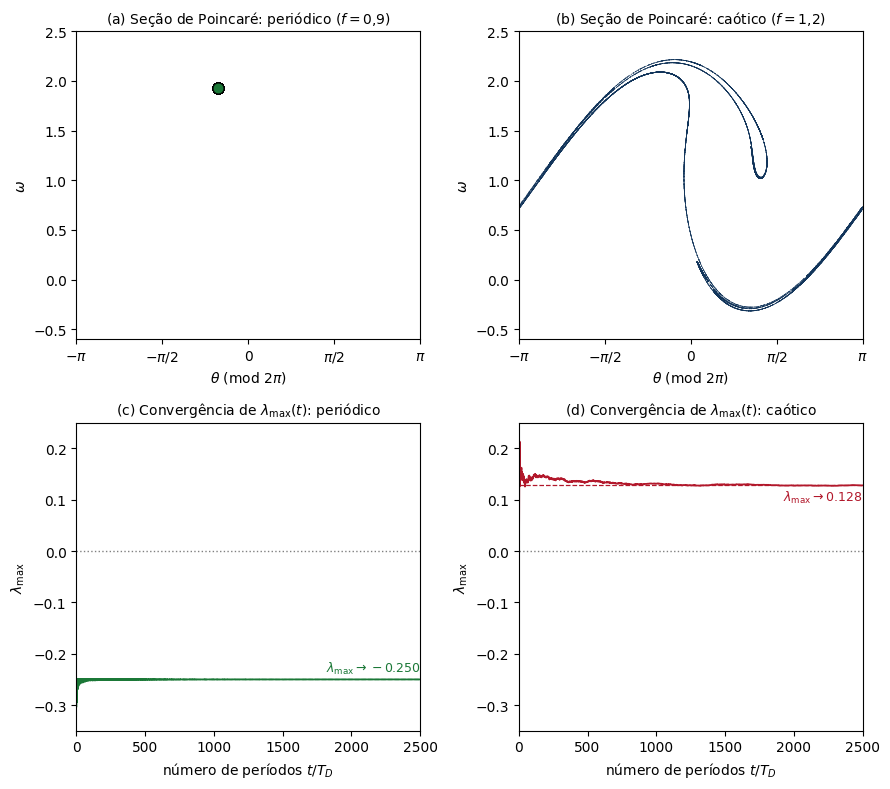

In [6]:
GREEN, NAVY, RED = '#1b7837', '#12355b', '#b2182b'
PI_TICKS  = [-math.pi, -math.pi/2, 0, math.pi/2, math.pi]
PI_LABELS = [r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$']

fig, ((ax_a, ax_b), (ax_c, ax_d)) = plt.subplots(2, 2, figsize=(9, 8))

# (a) e (b): seções de Poincaré
ax_a.scatter(TH_per, W_per, s=60, color=GREEN, edgecolors='k', linewidths=0.6, zorder=3)
ax_a.set_title(r'(a) Seção de Poincaré: periódico ($f=0{,}9$)', fontsize=10)
ax_b.scatter(TH_cao, W_cao, s=0.3, color=NAVY, edgecolors='none')
ax_b.set_title(r'(b) Seção de Poincaré: caótico ($f=1{,}2$)', fontsize=10)
for ax in (ax_a, ax_b):
    ax.set_xlim(-math.pi, math.pi)
    ax.set_ylim(-0.6, 2.5)
    ax.set_xticks(PI_TICKS, PI_LABELS)
    ax.set_xlabel(r'$\theta$ (mod $2\pi$)')
    ax.set_ylabel(r'$\omega$')

# (c) e (d): convergência de λ_max
n = np.arange(1, N_PLOT + 1)
paineis = ((ax_c, lam_per, GREEN, '(c)', 'periódico', 'bottom'),
           (ax_d, lam_cao, RED,   '(d)', 'caótico',   'top'))
for ax, lam, cor, letra, nome, va in paineis:
    lam_final = lam[N_PLOT - 1]
    ax.plot(n, lam[:N_PLOT], color=cor, lw=1.3)
    ax.axhline(lam_final, color=cor, ls='--', lw=0.9)
    ax.axhline(0, color='0.5', ls=':', lw=1)
    dy = 0.006 if va == 'bottom' else -0.006
    ax.text(N_PLOT, lam_final + dy, fr'$\lambda_{{\max}}\to{lam_final:.3f}$',
            color=cor, ha='right', va=va, fontsize=9)
    ax.set_xlim(0, N_PLOT)
    ax.set_ylim(-0.35, 0.25)
    ax.set_xlabel(r'número de períodos $t/T_D$')
    ax.set_ylabel(r'$\lambda_{\max}$')
    ax.set_title(fr'{letra} Convergência de $\lambda_{{\max}}(t)$: {nome}', fontsize=10)

fig.tight_layout()
fig.savefig(FIG_DIR / 'figura2_poincare_lyapunov.png', dpi=300, bbox_inches='tight')
plt.show()

## Leitura dos resultados

**Regime periódico ($f = 0{,}9$).** A seção se reduz a um único ponto, $(\theta, \omega) \approx (-0{,}56;\ 1{,}93)$: a órbita assintótica tem o mesmo período do forçamento. A média acumulada converge em poucas dezenas de períodos para $\lambda_{\max} = -0{,}250$, valor exato explicado na verificação acima. Perturbações são contraídas e o atrator é estável.

**Regime caótico ($f = 1{,}2$).** A seção é um conjunto filamentado, esticado e dobrado, em que os filamentos não se cruzam. A média acumulada oscila no início e se estabiliza em $\lambda_{\max} \approx 0{,}128$ após 2 500 períodos. Com os 30 000 períodos registrados a estimativa chega a $\approx 0{,}131$, e o espectro completo da Seção V (Notebook 05) dá $\lambda_1 \approx$ $0{,}1326 \pm 0{,}0012$. Estimativas de tempo finito diferem na terceira casa decimal, mas o sinal, que é o que distingue caos de ordem, não deixa dúvida.

A seção caótica sozinha não prova caos: uma nuvem de pontos também poderia vir de ruído ou de uma órbita de período muito longo. É $\lambda_{\max} > 0$ que confirma a sensibilidade às condições iniciais.

## Para explorar

- Troque `F_CAO` por outros valores de $f$ e compare com o diagrama de bifurcação do Notebook 03.
- Mude a condição inicial `TH0, W0`. Se a nova trajetória cair no mesmo atrator, a seção é a mesma, mas $\lambda_{\max}(n)$ oscila de outro modo antes de convergir.
- Reduza `SPP` para 50 e verifique se $\lambda_{\max}$ muda: é o teste de convergência do passo de integração.